# Wine Quality Prediction (WineQT dataset)

**Goal:** predict whether a red wine is *good* (quality ≥ 6) or *not good* (quality ≤ 5) from its chemical properties.

**Models:** Logistic Regression (L2 / Ridge), Random Forest, and Linear Regression (which predicts the numeric quality score; its output is also converted to good / not good so all three can be compared).


## 1. Import libraries

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, LinearRegression, Lasso
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay,
                             mean_squared_error, r2_score)



## 2. Load the data

In [5]:
df = pd.read_csv("WineQT.csv")
print("Shape (rows, columns):", df.shape)
df.head()

Shape (rows, columns): (1143, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,2
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,3
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,4


## 3. Basic cleaning

In [6]:
# Missing values and duplicates
print("Missing values per column:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

df.describe().T

Missing values per column:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
Id                      0
dtype: int64

Duplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
fixed acidity,1143.0,8.311111,1.747595,4.60000,7.10000,7.90000,9.100000,15.90000
volatile acidity,1143.0,0.531339,0.179633,0.12000,0.39250,0.52000,0.640000,1.58000
citric acid,1143.0,0.268364,0.196686,0.00000,0.09000,0.25000,0.420000,1.00000
residual sugar,1143.0,2.532152,1.355917,0.90000,1.90000,2.20000,2.600000,15.50000
chlorides,1143.0,0.086933,0.047267,0.01200,0.07000,0.07900,0.090000,0.61100
free sulfur dioxide,1143.0,15.615486,10.250486,1.00000,7.00000,13.00000,21.000000,68.00000
total sulfur dioxide,1143.0,45.914698,32.782130,6.00000,21.00000,37.00000,61.000000,289.00000
density,1143.0,0.996730,0.001925,0.99007,0.99557,0.99668,0.997845,1.00369
pH,1143.0,3.311015,0.156664,2.74000,3.20500,3.31000,3.400000,4.01000
sulphates,1143.0,0.657708,0.170399,0.33000,0.55000,0.62000,0.730000,2.00000


In [7]:
# 'Id' is just a row number, not a wine property, so it must not be used as a feature.
df = df.drop(columns=["Id"])

# The original target 'quality' is a score from 3 to 8. We turn it into a
# binary label (this is a classification problem).
df["good"] = (df["quality"] >= 6).astype(int)

print("Quality scores:")
print(df["quality"].value_counts().sort_index())
print("\nBinary target (1 = good, 0 = not good):")
print(df["good"].value_counts())
print(df["good"].value_counts(normalize=True).round(3))

Quality scores:
quality
3      6
4     33
5    483
6    462
7    143
8     16
Name: count, dtype: int64

Binary target (1 = good, 0 = not good):
good
1    621
0    522
Name: count, dtype: int64
good
1    0.543
0    0.457
Name: proportion, dtype: float64


**Why binary?** Only 6 wines have a score of 3 and 16 have a score of 8, so predicting the exact score would mean learning from very few examples. Splitting at 6 gives two groups of similar size, which makes accuracy, precision, recall and F1 easy to interpret.

## 4. Explore the data

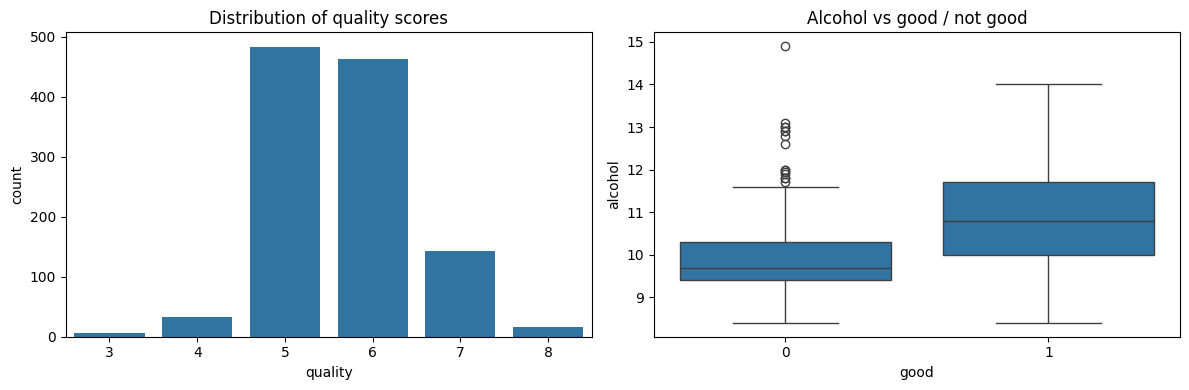

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(x="quality", data=df, ax=axes[0])
axes[0].set_title("Distribution of quality scores")

sns.boxplot(x="good", y="alcohol", data=df, ax=axes[1])
axes[1].set_title("Alcohol vs good / not good")
plt.tight_layout()
plt.show()

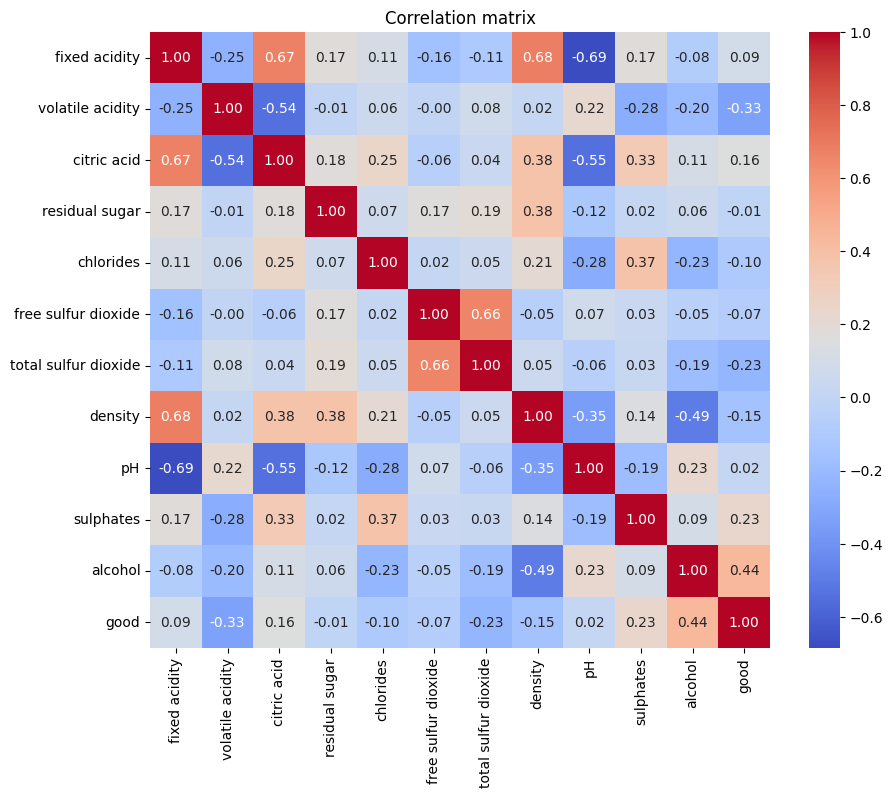

In [9]:
features = [c for c in df.columns if c not in ["quality", "good"]]

plt.figure(figsize=(10, 8))
sns.heatmap(df[features + ["good"]].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation matrix")
plt.show()

## 5. Multicollinearity check (VIF)

Highly correlated features (e.g. `fixed acidity`, `density`, `pH`, `citric acid`) can make regression coefficients unstable.
**VIF = 1 / (1 − R²)**, where R² comes from regressing one feature on all the others. A VIF above about 5–10 is a warning sign.

In [10]:
def compute_vif(data):
    vifs = {}
    for col in data.columns:
        X_other = data.drop(columns=[col])
        r2 = LinearRegression().fit(X_other, data[col]).score(X_other, data[col])
        vifs[col] = 1 / (1 - r2)
    return pd.Series(vifs).sort_values(ascending=False)

vif = compute_vif(df[features])
vif.round(2)

,0
fixed acidity,7.78
density,6.60
pH,3.39
citric acid,3.22
alcohol,3.18
total sulfur dioxide,2.10
free sulfur dioxide,1.91
volatile acidity,1.78
residual sugar,1.74
chlorides,1.54


If a feature has a very high VIF (here `fixed acidity` and `density` are the likely culprits), the usual fix is to remove it and recompute. Instead of removing features, I use **Ridge (L2) regularization** in the logistic regression, which shrinks the coefficients of correlated features and handles this problem. Plain linear regression has the same weakness (unstable weights), so I check its coefficients against Lasso later. Random Forest is not affected by multicollinearity in terms of prediction.

## 6. Split the data into training and test sets

In [11]:
X = df[features]
y = df["good"]

# stratify=y keeps the same good / not-good proportion in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Train size:", X_train.shape[0], "| Test size:", X_test.shape[0])

# Scale the features (fit on the TRAIN set only, to avoid leaking test information).
# Logistic regression needs scaled features; Random Forest does not.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Train size: 914 | Test size: 229


## 7. Model 1: Logistic Regression (L2 / Ridge)

Logistic regression passes a linear combination of the features through the **sigmoid function** to give a probability between 0 and 1. Its coefficients are found by **maximum likelihood estimation (MLE)**. In scikit-learn, `C` is the inverse of the regularization strength (smaller `C` = stronger penalty).

In [12]:
log_reg = LogisticRegression(C=1.0, max_iter=1000)
log_reg.fit(X_train_scaled, y_train)

y_pred_lr = log_reg.predict(X_test_scaled)

In [13]:
# Coefficients and odds ratios
# exp(coef) = how the ODDS of a wine being good change for a 1 standard deviation increase in that feature
coef_table = pd.DataFrame({
    "feature": features,
    "coefficient": log_reg.coef_[0],
    "odds_ratio": np.exp(log_reg.coef_[0])
}).sort_values("coefficient", ascending=False)
coef_table.round(3)

,feature,coefficient,odds_ratio
10,alcohol,1.027,2.792
9,sulphates,0.477,1.611
5,free sulfur dioxide,0.230,1.259
0,fixed acidity,0.203,1.225
7,density,0.059,1.061
8,pH,0.028,1.028
3,residual sugar,-0.034,0.966
4,chlorides,-0.107,0.898
2,citric acid,-0.290,0.748
6,total sulfur dioxide,-0.546,0.579


## 8. Model 2: Random Forest

Random Forest combines many decision trees. Each tree is trained on a **bootstrap sample** (this is **bagging**) and splits are chosen using impurity (entropy / information gain, or Gini).

In [14]:
rf = RandomForestClassifier(n_estimators=200, random_state=42)
rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)

## 9. Model 3: Linear Regression (predicting the quality score itself)

The first two models classify wines as good / not good. Linear regression instead predicts the numeric `quality` score:
ŷ = b₀ + b₁x₁ + ... + b₁₁x₁₁. Its weights are found by minimizing the MSE (ordinary least squares).

I use the **same train/test rows** as before (same `random_state`, `stratify=y`), so all three models are tested on identical wines.

In [15]:
y_num = df["quality"]
_, _, y_train_num, y_test_num = train_test_split(
    X, y_num, test_size=0.2, random_state=42, stratify=y
)
assert (y_train_num.index == y_train.index).all()   # same rows as the classifiers

lin_reg = LinearRegression()
lin_reg.fit(X_train_scaled, y_train_num)

pred_lin_train = lin_reg.predict(X_train_scaled)
pred_lin = lin_reg.predict(X_test_scaled)

mse = mean_squared_error(y_test_num, pred_lin)
print("Test MSE :", round(mse, 3))
print("Test RMSE:", round(np.sqrt(mse), 3), "(typical error in quality points)")
print("Test R2  :", round(r2_score(y_test_num, pred_lin), 3))
print("Train R2 :", round(r2_score(y_train_num, pred_lin_train), 3))

Test MSE : 0.423
Test RMSE: 0.65 (typical error in quality points)
Test R2  : 0.391
Train R2 : 0.366


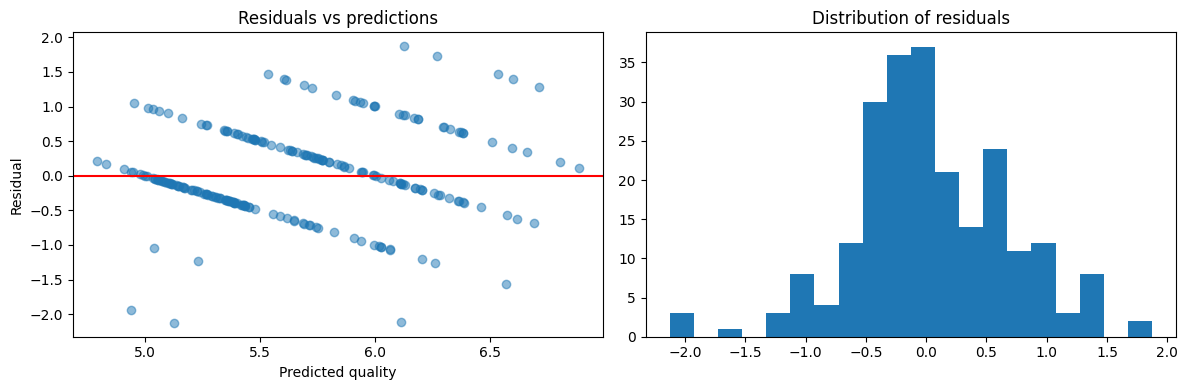

In [16]:
# Residuals = actual - predicted. A good model has residuals centred on 0 with no clear pattern.
residuals = y_test_num - pred_lin

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(pred_lin, residuals, alpha=0.5)
axes[0].axhline(0, color="red")
axes[0].set_xlabel("Predicted quality")
axes[0].set_ylabel("Residual")
axes[0].set_title("Residuals vs predictions")

axes[1].hist(residuals, bins=20)
axes[1].set_title("Distribution of residuals")
plt.tight_layout()
plt.show()

In [17]:
# Weights (features are standardized, so the weights are directly comparable).
# Lasso (L1) shrinks unimportant weights to exactly zero -> built-in feature selection.
lasso = Lasso(alpha=0.05)
lasso.fit(X_train_scaled, y_train_num)

weights = pd.DataFrame({
    "feature": features,
    "linear_weight": lin_reg.coef_,
    "lasso_weight": lasso.coef_,
}).sort_values("linear_weight", key=abs, ascending=False)

print("Lasso test R2:", round(r2_score(y_test_num, lasso.predict(X_test_scaled)), 3))
weights.round(3)

Lasso test R2: 0.355


,feature,linear_weight,lasso_weight
10,alcohol,0.314,0.285
1,volatile acidity,-0.191,-0.189
9,sulphates,0.145,0.072
6,total sulfur dioxide,-0.105,-0.035
4,chlorides,-0.086,-0.000
8,pH,-0.060,-0.000
5,free sulfur dioxide,0.036,-0.000
0,fixed acidity,-0.018,0.000
7,density,0.013,-0.000
3,residual sugar,-0.012,-0.000


In [18]:
# Turn the numeric predictions into good / not good so that linear regression can be
# compared with the classifiers: a predicted score of 5.5 or more means "good"
# (this matches the rule quality >= 6 after rounding).
y_pred_lin_train = (pred_lin_train >= 5.5).astype(int)
y_pred_lin = (pred_lin >= 5.5).astype(int)

## 10. Evaluation (all three models)

In [19]:
def evaluate(name, train_pred, test_pred):
    return {
        "Model": name,
        "Train accuracy": accuracy_score(y_train, train_pred),
        "Test accuracy": accuracy_score(y_test, test_pred),
        "Precision": precision_score(y_test, test_pred),
        "Recall": recall_score(y_test, test_pred),
        "F1-score": f1_score(y_test, test_pred),
    }

results = pd.DataFrame([
    evaluate("Logistic Regression (L2)", log_reg.predict(X_train_scaled), y_pred_lr),
    evaluate("Random Forest", rf.predict(X_train), y_pred_rf),
    evaluate("Linear Regression (score >= 5.5)", y_pred_lin_train, y_pred_lin),
]).set_index("Model")
results.round(3)

,Train accuracy,Test accuracy,Precision,Recall,F1-score
Model,,,,,
Logistic Regression (L2),0.764,0.777,0.802,0.782,0.792
Random Forest,1.000,0.812,0.805,0.863,0.833
Linear Regression (score >= 5.5),0.749,0.786,0.805,0.798,0.802


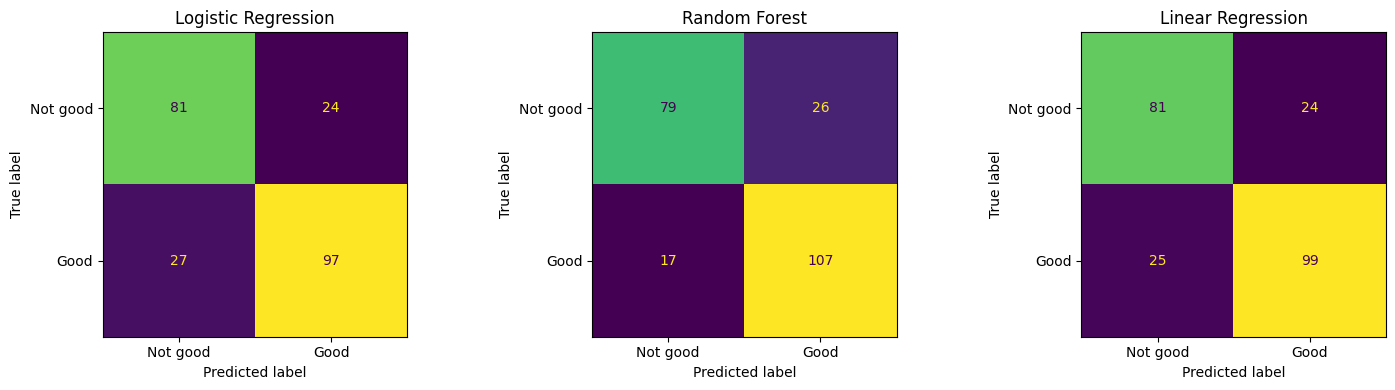

In [20]:
# Confusion matrices
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
panels = [("Logistic Regression", y_pred_lr), ("Random Forest", y_pred_rf), ("Linear Regression", y_pred_lin)]
for ax, (name, pred) in zip(axes, panels):
    cm = confusion_matrix(y_test, pred)
    ConfusionMatrixDisplay(cm, display_labels=["Not good", "Good"]).plot(ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

**Reading the numbers**
- **Accuracy** = correct predictions / all predictions.
- **Precision** = of the wines predicted *good*, how many really are good.
- **Recall** = of the wines that really are good, how many we found.
- **F1-score** = the balance between precision and recall.
- Compare **train accuracy vs test accuracy**: a large gap means **overfitting** (common for Random Forest, which can reach ~100% on training data).

## 11. Cross-validation

A single train/test split can be lucky or unlucky. 5-fold cross-validation gives a more reliable estimate.

In [23]:
cv_lr = cross_val_score(LogisticRegression(C=1.0, max_iter=1000),
                        scaler.fit_transform(X), y, cv=5, scoring="accuracy")
cv_rf = cross_val_score(RandomForestClassifier(n_estimators=200, random_state=42),
                        X, y, cv=5, scoring="accuracy")

print(f"Logistic Regression: mean = {cv_lr.mean():.3f}, std = {cv_lr.std():.3f}")
print(f"Random Forest:       mean = {cv_rf.mean():.3f}, std = {cv_rf.std():.3f}")

# Linear regression is a regression model, so it is scored with R2 on the numeric quality
cv_lin = cross_val_score(LinearRegression(), scaler.fit_transform(X), df["quality"], cv=5, scoring="r2")
print(f"Linear Regression:   mean R2 = {cv_lin.mean():.3f}, std = {cv_lin.std():.3f}")

Logistic Regression: mean = 0.744, std = 0.014
Random Forest:       mean = 0.729, std = 0.024
Linear Regression:   mean R2 = 0.311, std = 0.055


## 12. Which features matter most?

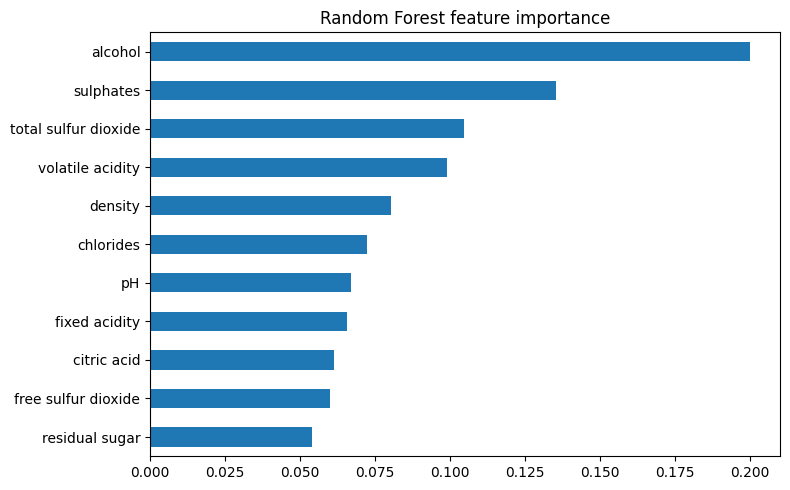

In [24]:
importances = pd.Series(rf.feature_importances_, index=features).sort_values()
importances.plot(kind="barh", figsize=(8, 5), title="Random Forest feature importance")
plt.tight_layout()
plt.show()

## 13. Gini vs entropy (how the trees choose their splits)

A decision tree picks the split that reduces impurity the most.
- **Entropy** = −Σ p·log₂(p); information gain = entropy before the split − weighted entropy after it (the ID3 rule).
- **Gini impurity** = 1 − Σ p²; the same idea, but cheaper to compute. It is scikit-learn's default.

In [25]:
for crit in ["gini", "entropy"]:
    model = RandomForestClassifier(n_estimators=200, criterion=crit, random_state=42)
    model.fit(X_train, y_train)
    print(f"{crit:8s} -> Random Forest test accuracy: {model.score(X_test, y_test):.3f}")

gini     -> Random Forest test accuracy: 0.812
entropy  -> Random Forest test accuracy: 0.808


## 14. Control overfitting with tree depth (bias–variance tradeoff)

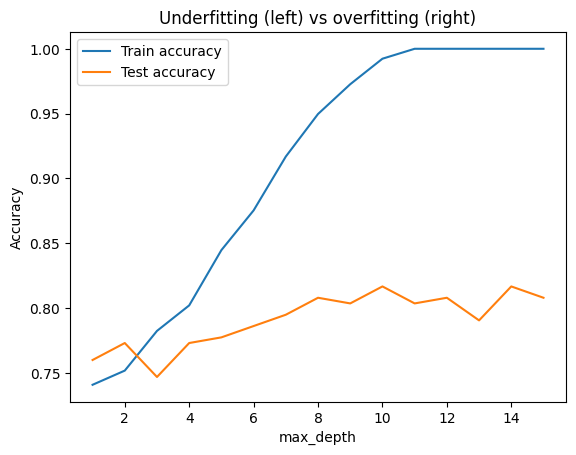

In [27]:
depths = range(1, 16)
train_acc, test_acc = [], []
for d in depths:
    m = RandomForestClassifier(n_estimators=100, max_depth=d, random_state=42).fit(X_train, y_train)
    train_acc.append(m.score(X_train, y_train))
    test_acc.append(m.score(X_test, y_test))

plt.plot(depths, train_acc, label="Train accuracy")
plt.plot(depths, test_acc, label="Test accuracy")
plt.xlabel("max_depth")
plt.ylabel("Accuracy")
plt.title("Underfitting (left) vs overfitting (right)")
plt.legend()
plt.show()